 Запуск на устройстве: cpu
 Генерация карт для обучения нейросети...
 Обучение нейросети...
Эпоха 1/10 | Loss: 1.3785
Эпоха 2/10 | Loss: 1.3833
Эпоха 3/10 | Loss: 1.3787
Эпоха 4/10 | Loss: 1.3769
Эпоха 5/10 | Loss: 1.3790
Эпоха 6/10 | Loss: 1.3770
Эпоха 7/10 | Loss: 1.3775
Эпоха 8/10 | Loss: 1.3753
Эпоха 9/10 | Loss: 1.3763
Эпоха 10/10 | Loss: 1.3750
 Проведение экспериментов на тестовых картах...
  -> Тестирование плотности 10%...
     Готово. Среднее время Euclidean: 4.02ms, Learned: 4.12ms
  -> Тестирование плотности 20%...
     Готово. Среднее время Euclidean: 3.34ms, Learned: 3.64ms
  -> Тестирование плотности 30%...
     Готово. Среднее время Euclidean: 2.36ms, Learned: 3.00ms
  -> Тестирование плотности 40%...
     Готово. Среднее время Euclidean: 1.05ms, Learned: 1.59ms
  -> Тестирование плотности 50%...
     Готово. Среднее время Euclidean: 0.44ms, Learned: 0.61ms
Построение графиков...


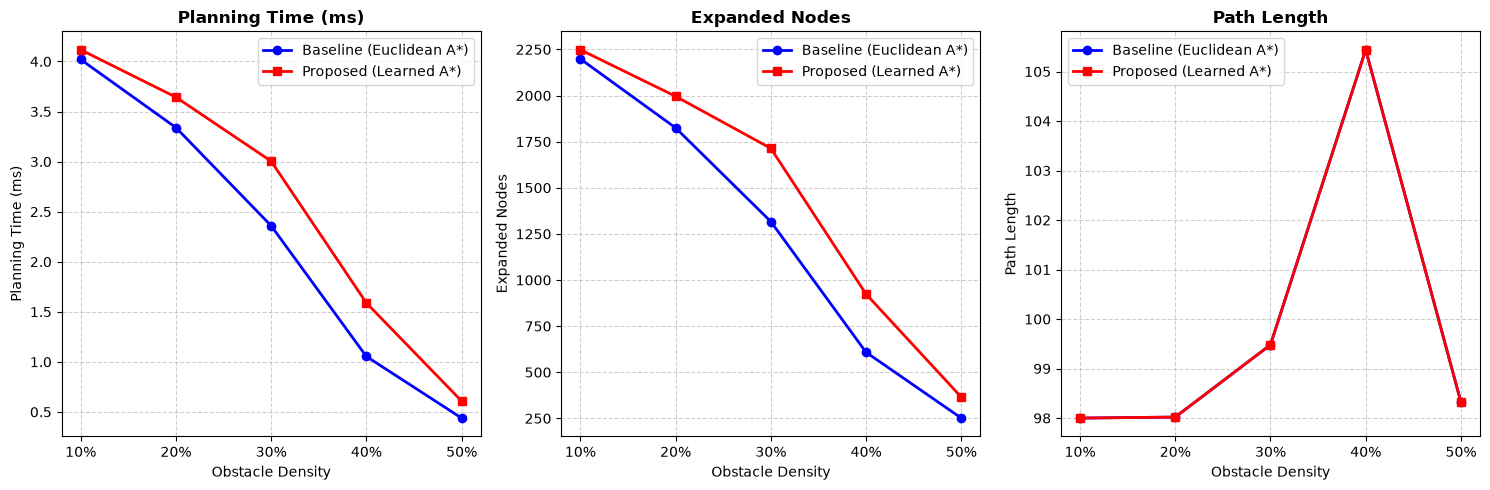

 Эксперимент успешно завершен! Сохраните графики через иконку дискеты в окне.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import time
import heapq
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import warnings
warnings.filterwarnings('ignore')

# НАСТРОЙКИ ЭКСПЕРИМЕНТА
MAP_SIZE = 50               
DENSITIES = [0.1, 0.2, 0.3, 0.4, 0.5] 
NUM_TRAIN_MAPS = 500
NUM_TEST_MAPS_PER_DENSITY = 20 
EPOCHS = 10                 
BATCH_SIZE = 32
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# 1. ГЕНЕРАЦИЯ КАРТ 
def generate_connected_map(size, density, start, goal):
    # 1. Генерируем случайный шум
    grid = np.random.choice([0, 1], size=(size, size), p=[1-density, density])
    grid[start] = 0
    grid[goal] = 0
    
    # 2. Пытаемся найти путь BFS
    visited = np.zeros((size, size), dtype=bool)
    queue = [start]
    visited[start] = True
    
    closest_to_goal = start
    min_dist_to_goal = float('inf')
    
    while queue:
        x, y = queue.pop(0)
        
        # Запоминаем точку, которую BFS смог достичь и которая ближе всего к цели
        dist = np.sqrt((x-goal[0])**2 + (y-goal[1])**2)
        if dist < min_dist_to_goal:
            min_dist_to_goal = dist
            closest_to_goal = (x, y)
            
        if (x, y) == goal:
            break # Путь найден, выходим
            
        for dx, dy in [(-1,0), (1,0), (0,-1), (0,1)]:
            nx, ny = x+dx, y+dy
            if 0 <= nx < size and 0 <= ny < size and not visited[nx, ny] and grid[nx, ny] == 0:
                visited[nx, ny] = True
                queue.append((nx, ny))
                
    # 3. Если путь не найден пробиваем "туннель"
    if not visited[goal]:
        cx, cy = closest_to_goal
        gx, gy = goal
        
        # Пробиваем коридор по оси X
        while cx != gx:
            cx += 1 if gx > cx else -1
            grid[cx, cy] = 0 # Делаем клетку свободной
            
        # Пробиваем коридор по оси Y
        while cy != gy:
            cy += 1 if gy > cy else -1
            grid[cx, cy] = 0 
            
    return grid

def compute_ground_truth_h(grid, goal):
    # Считаем расстояние только для достижимых клеток
    size = grid.shape[0]
    h = np.full((size, size), -1.0) 
    h[goal] = 0
    queue = [goal]
    while queue:
        x, y = queue.pop(0)
        for dx, dy in [(-1,0), (1,0), (0,-1), (0,1)]:
            nx, ny = x+dx, y+dy
            if 0 <= nx < size and 0 <= ny < size and grid[nx, ny] == 0 and h[nx, ny] == -1.0:
                h[nx, ny] = h[x, y] + 1
                queue.append((nx, ny))
    return h

def compute_euclidean_h(size, goal):
    y, x = np.ogrid[:size, :size]
    return np.sqrt((x - goal[1])**2 + (y - goal[0])**2)

# 2. НЕЙРОСЕТЬ 
class MapDataset(Dataset):
    def __init__(self, grids, gt_hs, goal_hs):
        self.grids, self.gt_hs, self.goal_hs = grids, gt_hs, goal_hs
    def __len__(self): return len(self.grids)
    def __getitem__(self, idx):
        grid_t = torch.tensor(self.grids[idx], dtype=torch.float32).unsqueeze(0)
        goal_h_t = torch.tensor(self.goal_hs[idx], dtype=torch.float32).unsqueeze(0) / MAP_SIZE
        
        # Берем только достижимые клетки (где gt_h >= 0)
        valid_mask = (self.gt_hs[idx] >= 0).astype(np.float32)
        mask_t = torch.tensor(valid_mask, dtype=torch.float32).unsqueeze(0)
        
        # Ограничиваем целевые значения, чтобы избежать взрыва градиентов
        gt_h_clipped = np.clip(self.gt_hs[idx], 0, MAP_SIZE * 2)
        gt_h_t = torch.tensor(gt_h_clipped, dtype=torch.float32).unsqueeze(0) / MAP_SIZE
        
        return torch.cat([grid_t, goal_h_t], dim=0), gt_h_t, mask_t

class HeuristicCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(2, 16, kernel_size=3, padding=1), nn.ReLU(),
            nn.Conv2d(16, 32, kernel_size=3, padding=1), nn.ReLU(),
            nn.Conv2d(32, 16, kernel_size=3, padding=1), nn.ReLU(),
            nn.Conv2d(16, 1, kernel_size=3, padding=1),
            nn.ReLU() # Добавили ReLU, чтобы эвристика не была отрицательной
        )
    def forward(self, x): return self.net(x)

# 3. АЛГОРИТМ A* 
def astar(grid, start, goal, h_map):
    size = grid.shape[0]
    open_set = []
    heapq.heappush(open_set, (0, start))
    g_score = {start: 0}
    came_from = {}
    expanded_nodes = 0
    
    max_nodes = 10000 
    
    while open_set and expanded_nodes < max_nodes:
        _, current = heapq.heappop(open_set)
        expanded_nodes += 1
        
        if current == goal:
            path_len = 0
            curr = current
            while curr in came_from:
                curr = came_from[curr]
                path_len += 1
            return path_len, expanded_nodes
            
        for dx, dy in [(-1,0), (1,0), (0,-1), (0,1)]:
            nx, ny = current[0]+dx, current[1]+dy
            if 0 <= nx < size and 0 <= ny < size and grid[nx, ny] == 0:
                neighbor = (nx, ny)
                tentative_g = g_score[current] + 1
                if neighbor not in g_score or tentative_g < g_score[neighbor]:
                    came_from[neighbor] = current
                    g_score[neighbor] = tentative_g
                    
                    # Защита от NaN/Inf в эвристике
                    h_val = h_map[nx, ny]
                    if np.isnan(h_val) or np.isinf(h_val):
                        h_val = 0.0
                        
                    heapq.heappush(open_set, (tentative_g + h_val, neighbor))
                    
    # Если путь не найден или превышен лимит узлов
    return -1, expanded_nodes

# 4. ГЛАВНАЯ ФУНКЦИЯ 
def main():
    print(f" Запуск на устройстве: {DEVICE}")
    start_pos, goal_pos = (0, 0), (MAP_SIZE-1, MAP_SIZE-1)
    
    print(" Генерация карт для обучения нейросети...")
    train_grids, train_gt_hs, train_goal_hs = [], [], []
    euclidean_h_map = compute_euclidean_h(MAP_SIZE, goal_pos)
    
    for _ in range(NUM_TRAIN_MAPS):
        density = np.random.uniform(0.1, 0.5)
        grid = generate_connected_map(MAP_SIZE, density, start_pos, goal_pos)
        train_grids.append(grid)
        train_gt_hs.append(compute_ground_truth_h(grid, goal_pos))
        train_goal_hs.append(euclidean_h_map)
        
    dataloader = DataLoader(MapDataset(train_grids, train_gt_hs, train_goal_hs), batch_size=BATCH_SIZE, shuffle=True)
    
    print(" Обучение нейросети...")
    model = HeuristicCNN().to(DEVICE)
    optimizer = optim.Adam(model.parameters(), lr=0.001)
    criterion = nn.MSELoss(reduction='none')
    
    for epoch in range(EPOCHS):
        total_loss = 0
        count = 0
        for inputs, targets, masks in dataloader:
            inputs, targets, masks = inputs.to(DEVICE), targets.to(DEVICE), masks.to(DEVICE)
            optimizer.zero_grad()
            outputs = model(inputs)
            
            # Считаем loss только по достижимым клеткам
            loss = (criterion(outputs, targets) * masks).sum() / (masks.sum() + 1e-8)
            loss.backward()
            
            # Обрезаем градиенты
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            
            optimizer.step()
            total_loss += loss.item()
            count += 1
            
        print(f"Эпоха {epoch+1}/{EPOCHS} | Loss: {total_loss/count:.4f}")
    model.eval()
    
    print(" Проведение экспериментов на тестовых картах...")
    results = {d: {'euclidean': {'time': [], 'nodes': [], 'path': []},
                   'learned': {'time': [], 'nodes': [], 'path': []}} for d in DENSITIES}
                   
    for density in DENSITIES:
        print(f"  -> Тестирование плотности {int(density*100)}%...")
        for i in range(NUM_TEST_MAPS_PER_DENSITY):
            grid = generate_connected_map(MAP_SIZE, density, start_pos, goal_pos)
            
            # 1. Baseline: A* с евклидовой эвристикой
            t0 = time.time()
            path_euc, nodes_euc = astar(grid, start_pos, goal_pos, euclidean_h_map)
            time_euc = (time.time() - t0) * 1000 
            
                # 2. Proposed: A* с эвристикой от нейросети
            with torch.no_grad():
                grid_t = torch.tensor(grid, dtype=torch.float32).unsqueeze(0).unsqueeze(0).to(DEVICE)
                goal_h_t = torch.tensor(euclidean_h_map, dtype=torch.float32).unsqueeze(0).unsqueeze(0).to(DEVICE) / MAP_SIZE
                h_learned_map = model(torch.cat([grid_t, goal_h_t], dim=1)).squeeze().cpu().numpy()
                
            h_learned_map = h_learned_map * MAP_SIZE 
            
            t0 = time.time()
            path_learned, nodes_learned = astar(grid, start_pos, goal_pos, h_learned_map)
            time_learned = (time.time() - t0) * 1000 
            
            if path_euc != -1 and path_learned != -1:
                for metric, val_euc, val_learned in zip(['time', 'nodes', 'path'], 
                                                        [time_euc, nodes_euc, path_euc], 
                                                        [time_learned, nodes_learned, path_learned]):
                    results[density]['euclidean'][metric].append(val_euc)
                    results[density]['learned'][metric].append(val_learned)
                    
        print(f"     Готово. Среднее время Euclidean: {np.mean(results[density]['euclidean']['time']):.2f}ms, Learned: {np.mean(results[density]['learned']['time']):.2f}ms")

    print("Построение графиков...")
    plot_results(results)

def plot_results(results):
    fig, axs = plt.subplots(1, 3, figsize=(15, 5))
    densities = list(results.keys())
    x_labels = [f"{int(d*100)}%" for d in densities]
    
    metrics = [('time', 'Planning Time (ms)'), ('nodes', 'Expanded Nodes'), ('path', 'Path Length')]
    
    for ax, (metric, title) in zip(axs, metrics):
        vals_euc = [np.mean(results[d]['euclidean'][metric]) for d in densities]
        vals_learned = [np.mean(results[d]['learned'][metric]) for d in densities]
        
        ax.plot(x_labels, vals_euc, marker='o', label='Baseline (Euclidean A*)', color='blue', linewidth=2)
        ax.plot(x_labels, vals_learned, marker='s', label='Proposed (Learned A*)', color='red', linewidth=2)
        ax.set_title(title, fontsize=12, fontweight='bold')
        ax.set_xlabel('Obstacle Density', fontsize=10)
        ax.set_ylabel(title, fontsize=10)
        ax.legend()
        ax.grid(True, linestyle='--', alpha=0.6)
        
    plt.tight_layout()
    plt.show()
    print(" Эксперимент успешно завершен! Сохраните графики через иконку дискеты в окне.")

if __name__ == "__main__":
    main()